In [12]:
#kullanacağım kütüphaneleri çağrıyorum
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


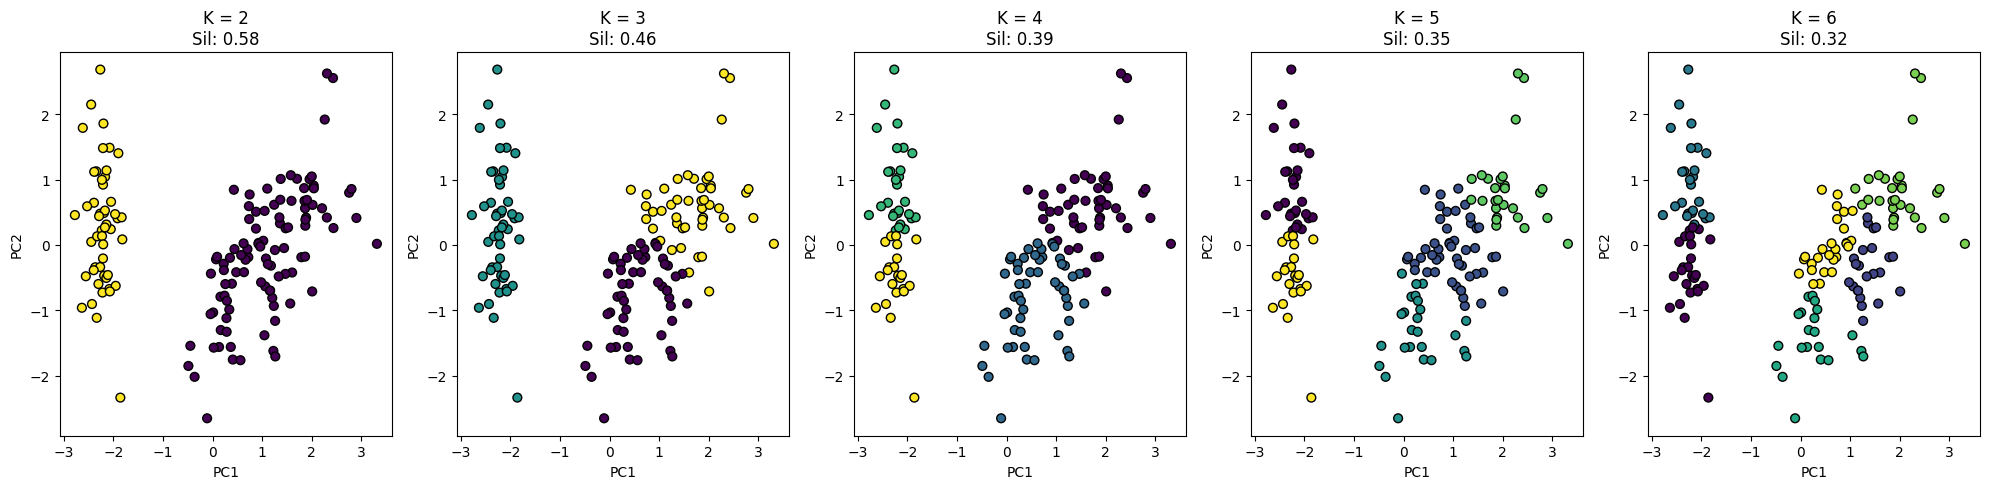


--- Kümeleme Sayısına Göre Başarı Metrikleri ---
   K  Silhouette  Davies-Bouldin
0  2    0.581750        0.593313
1  3    0.459948        0.833595
2  4    0.386941        0.869814
3  5    0.345901        0.948317
4  6    0.317079        1.053677


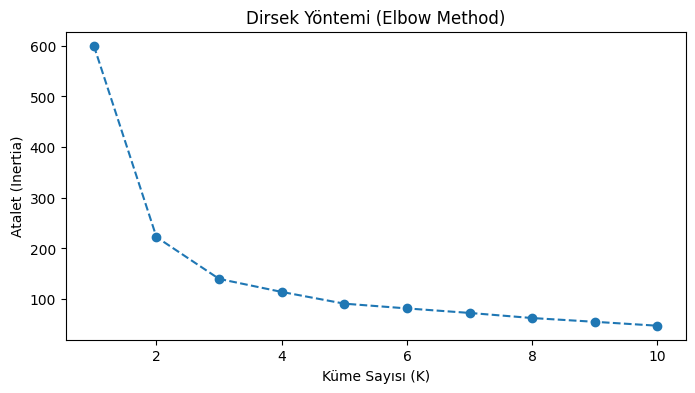

In [14]:
iris = load_iris()
X = iris.data
y = iris.target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA ile 2 boyuta indirgeme (Sadece görselleştirme için)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# küme sayısı denemeleri
cluster_counts = [2, 3, 4, 5, 6] 

# Sonuçları tutmak için boş liste
results = []

# Görselleştirme için alt alta grafikler
fig, axes = plt.subplots(1, len(cluster_counts), figsize=(20, 5))

# 3. Döngü
for i, n in enumerate(cluster_counts):
    km = KMeans(n_clusters=n, init='k-means++', n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    
    sil_score = silhouette_score(X_scaled, labels)
    db_index = davies_bouldin_score(X_scaled, labels)
    
    results.append({'K': n, 'Silhouette': sil_score, 'Davies-Bouldin': db_index})
    
    axes[i].scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis', s=40, edgecolors='k')
    axes[i].set_title(f"K = {n}\nSil: {sil_score:.2f}")
    axes[i].set_xlabel("PC1")
    axes[i].set_ylabel("PC2")

plt.tight_layout()
plt.show()

# 4. Skorları Karşılaştırmalı Tablo Olarak Göstericem
import pandas as pd
df_results = pd.DataFrame(results)
print("\n--- Kümeleme Sayısına Göre Başarı Metrikleri ---")
print(df_results)

# 5. Dirsek (Elbow) Yöntemi için Atalet Grafiği (Ekstra)
inertias = []
for n in range(1, 11):
    km = KMeans(n_clusters=n, random_state=42, n_init=10).fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), inertias, marker='o', linestyle='--')
plt.title('Dirsek Yöntemi (Elbow Method)')
plt.xlabel('Küme Sayısı (K)')
plt.ylabel('Atalet (Inertia)')
plt.show()

SKORLAR VE ELBOW METHODA BAKILDIĞINDA UYGUN OLAN KÜME SAYISININ 2-3 KÜME OLDUĞUNU SÖYLEYEBİLİRİZ.